# My thyroid labs vs. the Kaggle pop

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

DATA = Path("..") / "data"
GROUP_BY_CODE = {**{c: "hyper" for c in "ABCD"}, **{c: "hypo" for c in "EFGH"}, "-": "normal"}

kaggle = pd.read_csv(DATA / "thyroidDF.csv", usecols=["age", "sex", "TSH", "T3", "target"])
kaggle["group"] = kaggle["target"].astype(str).str[0].map(GROUP_BY_CODE)
kaggle = kaggle.dropna(subset=["group", "TSH"]).copy()
kaggle["TSH"] = kaggle["TSH"].clip(lower=0.005)  # log scale needs positive values

personal = pd.read_csv(DATA / "personal_thyroid.csv", usecols=["date", "TSH", "T3", "lab_status", "methimazole_mg"])
personal["date"] = pd.to_datetime(personal["date"], format="mixed")
personal = personal.sort_values("date").dropna(subset=["TSH"]).reset_index(drop=True)

GROUP_COLORS = {"hyper": "#e34948", "normal": "#1baf7a", "hypo": "#2a78d6"}
STATUS_COLORS = {**GROUP_COLORS, "subclinical_hyper": "#eda100", "subclinical_hypo": "#6250d6",
                 "euthyroid": GROUP_COLORS["normal"], "hyperthyroid": GROUP_COLORS["hyper"],
                 "hypothyroid": GROUP_COLORS["hypo"]}
SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#a3a29c"
TSH_RANGE = (0.4, 4.0)  # typical adult range, not your lab's own

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
})

kaggle["group"].value_counts().rename("Kaggle patients with TSH").to_frame()

,Kaggle patients with TSH
group,
normal,6082
hypo,666
hyper,207


## 1. TSH distribution by group, with your draws underneath

Each ridge is the density of log TSH for that group, with a line at the group median. Your draws sit in the bottom row, colored by your own lab status, so you can see whether your status matches the group your TSH resembles.

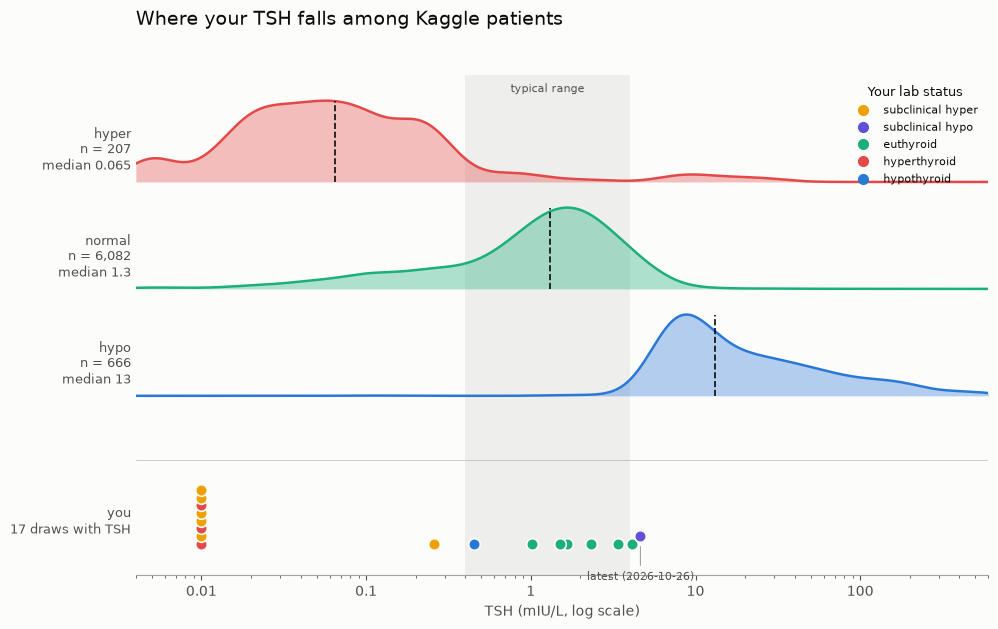

In [ ]:
x = np.linspace(np.log10(0.004), np.log10(600), 500)


def density(values, bandwidth=0.15):
    log_vals = np.log10(values)
    d = np.exp(-0.5 * ((x[:, None] - log_vals[None, :]) / bandwidth) ** 2).sum(axis=1)
    return d / d.max()


ROW_ORDER = ["hyper", "normal", "hypo"]
bases = {g: 0.6 + (len(ROW_ORDER) - i) * 1.25 for i, g in enumerate(ROW_ORDER)}
you_base = 0.0

fig, ax = plt.subplots(figsize=(11, 6.5))
ax.axvspan(*TSH_RANGE, color=MUTED, alpha=0.15, lw=0)
ax.text(np.sqrt(TSH_RANGE[0] * TSH_RANGE[1]), bases["hyper"] + 1.05, "typical range", ha="center", fontsize=8, color=INK2)

tick_labels = []
for g in ROW_ORDER:
    vals = kaggle.loc[kaggle["group"] == g, "TSH"].to_numpy()
    d = density(vals)
    ax.fill_between(10 ** x, bases[g], bases[g] + 0.95 * d, color=GROUP_COLORS[g], alpha=0.35, lw=0)
    ax.plot(10 ** x, bases[g] + 0.95 * d, color=GROUP_COLORS[g], lw=1.8)
    ax.plot([np.median(vals)] * 2, [bases[g], bases[g] + 0.95], color=INK, lw=1.2, ls="--")
    tick_labels.append(f"{g}\nn = {len(vals):,}\nmedian {np.median(vals):.2g}")

# Your draws: dodge vertically so repeated values stay visible.
seen = {}
for _, r in personal.iterrows():
    key = round(np.log10(r["TSH"]) * 8)
    k = seen.get(key, 0)
    seen[key] = k + 1
    y = you_base + 0.12 + 0.09 * k
    color = STATUS_COLORS[r["lab_status"]]
    ax.scatter(r["TSH"], y, s=70, zorder=3, color=color, edgecolor=SURFACE, lw=1.2)

latest = personal.iloc[-1]
ax.annotate(f"latest ({latest['date']:%Y-%m-%d})", (latest["TSH"], you_base + 0.12),
            xytext=(0, -26), textcoords="offset points", ha="center", fontsize=8, color=INK2,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
tick_labels.append(f"you\n{len(personal)} draws with TSH")
ax.axhline(1.1, color=MUTED, lw=0.6, alpha=0.6)

ax.set_xscale("log")
ax.set_xlim(0.004, 600)
ax.set_ylim(-0.25, 5.6)
ax.set_yticks([bases[g] + 0.4 for g in ROW_ORDER] + [you_base + 0.4])
ax.set_yticklabels(tick_labels, fontsize=9)
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.set_xlabel("TSH (mIU/L, log scale)")
ax.set_xticks([0.01, 0.1, 1, 10, 100])
ax.set_xticklabels(["0.01", "0.1", "1", "10", "100"])
status_handles = [Line2D([], [], marker="o", ls="", color=c, label=s.replace("_", " "), markersize=7)
                  for s, c in STATUS_COLORS.items() if s in set(personal["lab_status"])]
ax.legend(handles=status_handles, title="Your lab status", frameon=False, loc="upper right", fontsize=8, title_fontsize=9)
fig.suptitle("Where your TSH falls among Kaggle patients", x=0.125, ha="left", fontsize=14)
fig.savefig("population_tsh.png", dpi=110, bbox_inches="tight")
plt.show()